# Bian et al. (2021) DTNN: Panasonic to CMU eVTOL

This notebook runs the supervised DTNN/MDA extension on the CMU core-seven protocol. It uses the paper-aligned serial `CNN1 -> CNN2 -> two-layer BiLSTM -> FC` network, sequence-to-sequence SOC regression, and MMD at CNN2, BiLSTM2, and FC.

CMU `soc_dynamic` is a development reference, not laboratory ground truth; these runs are not formal-benchmark eligible. Add a Colab Secret named `GITHUB_TOKEN`, enable Notebook access, and select a GPU runtime before the formal run.

In [1]:
from pathlib import Path
import os, subprocess, sys, tempfile
from urllib.parse import urlunsplit

from google.colab import drive, userdata
drive.mount('/content/drive')

REPO = Path('/content/battery-soc-transfer-benchmark')
REPO_URL = urlunsplit(('https', 'github.com', '/zhangcastle/battery-soc-transfer-benchmark.git', '', ''))
github_token = userdata.get('GITHUB_TOKEN')
if not github_token:
    raise RuntimeError('Add the GITHUB_TOKEN Colab Secret and enable Notebook access')
if REPO.exists() and not (REPO / '.git').exists():
    raise RuntimeError(f'Remove incomplete checkout and rerun: {REPO}')
with tempfile.TemporaryDirectory() as temp_dir:
    askpass = Path(temp_dir) / 'git-askpass.sh'
    askpass.write_text('#!/bin/sh\ncase "$1" in\n*Username*) echo "x-access-token" ;;\n*) printf "%s" "$GITHUB_TOKEN" ;;\nesac\n')
    askpass.chmod(0o700)
    git_env = os.environ.copy()
    git_env.update({'GIT_ASKPASS': str(askpass), 'GIT_TERMINAL_PROMPT': '0', 'GITHUB_TOKEN': github_token})
    command = (['git', '-C', str(REPO), 'pull', '--ff-only'] if (REPO / '.git').exists() else ['git', 'clone', '--depth', '1', REPO_URL, str(REPO)])
    result = subprocess.run(command, env=git_env, text=True, capture_output=True)
del github_token
if result.returncode:
    raise RuntimeError('Authenticated GitHub setup failed; check token permission')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO)], check=True)
os.chdir(REPO)
src_path = str(REPO / 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)
print('Repository ready:', subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip())

Mounted at /content/drive
Repository ready: 835db6f3ddd3c80d29dcf9895ae0d4198524a51f


## Protocol

- Source: Panasonic NCR18650PF at 25, 10, 0, -10, and -20 C; Cycle 1-4, NN, US06, and HWFET.
- Inputs: current and voltage, normalized with the combined Panasonic source ranges; target data do not fit a scaler.
- Windows: 20 steps, non-overlapping; every step has an SOC target. The paper leaves M unspecified, and 20 keeps the short-cruise CMU condition eligible.
- CMU adaptation: chronological complete-mission prefix matching 8,778 seconds. Each mission starts at 70% SOC; its first 30% is labelled for adaptation.
- Held-out test missions also start at 70% SOC and are evaluated on the remaining 70%. Every cell and repeat starts from its source-pretrained state.
- Objective: source MSE + `5 * target MSE + 0.1 * adaptive multiscale MMD`.
- `formal` keeps the validated screening model and epoch counts, but repeats five seeds for uncertainty reporting.

In [2]:
import pandas as pd
import torch
from IPython.display import display
from battery_benchmark.utils.config import load_yaml

PATHS = load_yaml(REPO / 'configs/paths/colab_drive.yaml')
PANASONIC_ROOT = Path(PATHS['raw_data_root']) / 'Panasonic_18650PF'
CMU_BASE_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel'
CMU_CONDITION_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel'
CMU_MANIFEST = REPO / 'data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv'
RUN_MODE = 'formal'
RUN_EXPERIMENT = True

SETTINGS = {
    'screening': dict(
        source_epochs=2000,
        transfer_epochs=330,
        repeats=1,
        batch_size=64,
        lightweight=False,
    ),
    'formal': dict(
        source_epochs=2000,
        transfer_epochs=330,
        repeats=5,
        batch_size=64,
        lightweight=False,
    ),
}
setting = SETTINGS[RUN_MODE]
INITIAL_SOC = 0.70
RESULT_ROOT = Path(PATHS['output_root']) / 'benchmarks/panasonic_to_cmu_evtol/bian_2021/initial_soc_70_v2' / RUN_MODE
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if RUN_MODE == 'formal' and DEVICE != 'cuda':
    raise RuntimeError('Select a Colab GPU runtime for the formal run')
print('mode:', RUN_MODE, setting)
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')
print('output:', RESULT_ROOT)

mode: formal {'source_epochs': 2000, 'transfer_epochs': 330, 'repeats': 5, 'batch_size': 64, 'lightweight': False}
device: cuda NVIDIA L4
output: /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/bian_2021/initial_soc_70_v2/formal


In [3]:
required = [PANASONIC_ROOT, CMU_BASE_ROOT, CMU_CONDITION_ROOT, CMU_MANIFEST, REPO / 'scripts/benchmarks/run_bian_cmu.py']
for path in required:
    assert path.exists(), f'Missing required input: {path}'
cmu_files = sorted(CMU_BASE_ROOT.glob('*_dynamic_soc.parquet')) + sorted(CMU_CONDITION_ROOT.glob('*_dynamic_soc.parquet'))
assert len(cmu_files) == 7, f'Expected seven CMU cell files, found {len(cmu_files)}'
display(pd.DataFrame({'path': [str(p) for p in cmu_files], 'size_mb': [round(p.stat().st_size / 1e6, 1) for p in cmu_files]}))
print('Panasonic MAT files:', len(list(PANASONIC_ROOT.rglob('*.mat'))))
print('Preflight passed. Set RUN_EXPERIMENT=True in the config cell to train.')

,path,size_mb
0,/content/battery-soc-transfer-benchmark/output...,28.3
1,/content/battery-soc-transfer-benchmark/output...,14.8
2,/content/battery-soc-transfer-benchmark/output...,9.7
3,/content/battery-soc-transfer-benchmark/output...,29.7
4,/content/battery-soc-transfer-benchmark/output...,26.7
5,/content/battery-soc-transfer-benchmark/output...,9.2
6,/content/battery-soc-transfer-benchmark/output...,13.5


Panasonic MAT files: 51
Preflight passed. Set RUN_EXPERIMENT=True in the config cell to train.


In [4]:
if RUN_EXPERIMENT:
    command = [
        sys.executable, str(REPO / 'scripts/benchmarks/run_bian_cmu.py'),
        '--panasonic-data-root', str(PANASONIC_ROOT),
        '--cmu-base-root', str(CMU_BASE_ROOT),
        '--cmu-condition-root', str(CMU_CONDITION_ROOT),
        '--cmu-manifest', str(CMU_MANIFEST),
        '--output-root', str(RESULT_ROOT),
        '--initial-soc', str(INITIAL_SOC),
        '--sequence-length', '20',
        '--source-epochs', str(setting['source_epochs']),
        '--transfer-epochs', str(setting['transfer_epochs']),
        '--repeats', str(setting['repeats']),
        '--batch-size', str(setting['batch_size']),
        '--transfer-lr', '1e-4',
        '--transfer-batch-size', '16',
        '--device', DEVICE,
    ]
    if setting['lightweight']:
        command.append('--lightweight')
    print('Running:', ' '.join(command))
    subprocess.run(command, check=True)
else:
    print('Dry run only. Set RUN_EXPERIMENT=True in the config cell when ready.')

Running: /usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/benchmarks/run_bian_cmu.py --panasonic-data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --cmu-base-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel --cmu-condition-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel --cmu-manifest /content/battery-soc-transfer-benchmark/data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/bian_2021/initial_soc_70_v2/formal --initial-soc 0.7 --sequence-length 20 --source-epochs 2000 --transfer-epochs 330 --repeats 5 --batch-size 64 --transfer-lr 1e-4 --transfer-batch-size 16 --device cuda


In [5]:
metrics_path = RESULT_ROOT / 'metrics.csv'
if metrics_path.exists():
    metrics = pd.read_csv(metrics_path)
    display(metrics.pivot_table(index=['cell_id', 'initial_soc_percent'], columns='method', values=['overall_mae_percent', 'overall_rmse_percent'], aggfunc='mean').round(3))
    aggregate = metrics.groupby('method')[['overall_mae_percent', 'overall_rmse_percent']].mean().round(3)
    display(aggregate.style.set_caption('Core-seven mean (%)'))
    rmse = metrics.pivot_table(index='cell_id', columns='method', values='overall_rmse_percent', aggfunc='mean')
    display((rmse['Bian MDA'] - rmse['Source only']).rename('MDA_minus_source_RMSE_points').round(3).to_frame())
    print('Metadata:', RESULT_ROOT / 'run.json')
else:
    print('No result yet:', metrics_path)

overall_mae_percent              \
method                                 Bian MDA Source only   
cell_id initial_soc_percent                                   
VAH01   70                                6.110       9.418   
VAH11   70                                5.486       7.426   
VAH12   70                               10.251      12.905   
VAH15   70                                6.771      10.651   
VAH17   70                                7.202      10.595   
VAH27   70                                6.153      10.174   
VAH30   70                                8.137      13.062   

                            overall_rmse_percent              
method                                  Bian MDA Source only  
cell_id initial_soc_percent                                   
VAH01   70                                 8.190      11.012  
VAH11   70                                 7.363      11.911  
VAH12   70                                11.516      15.576  
VAH15   70                                 8.954      11.500  
VAH17   70                                 9.450      12.011  
VAH27   70                                 8.201      11.593  
VAH30   70                                10.990      14.106

,overall_mae_percent,overall_rmse_percent
method,,
Bian MDA,7.159000,9.238000
Source only,10.604000,12.530000


,MDA_minus_source_RMSE_points
cell_id,
VAH01,-2.822
VAH11,-4.548
VAH12,-4.061
VAH15,-2.546
VAH17,-2.561
VAH27,-3.392
VAH30,-3.115


Metadata: /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/bian_2021/initial_soc_70_v2/formal/run.json


## Diagnostics (Vidal-alignment additions)

Everything below is read-only reporting on files `run_bian_cmu.py` already writes (`training_history.csv`, `test_predictions.parquet`, `run.json`) -- none of it changes what was trained or evaluated. It adapts to the updated schema (`ns_raw`/`mission_phase` alongside the existing `development_phase_role`/raw V-I-T/capacity-provenance columns) added for cross-benchmark comparison with the Vidal CMU notebook (`01_vidal_lstm_tl.ipynb`); DTNN's own training/adaptation/evaluation code is untouched.

In [6]:
import json

training_history_path = RESULT_ROOT / 'training_history.csv'
source_training_history_path = RESULT_ROOT / 'source_training_history.csv'
test_predictions_path = RESULT_ROOT / 'test_predictions.parquet'
run_metadata_path = RESULT_ROOT / 'run.json'

training_history = (
    pd.read_csv(training_history_path) if training_history_path.exists() else pd.DataFrame()
)
source_training_history = (
    pd.read_csv(source_training_history_path)
    if source_training_history_path.exists() else pd.DataFrame()
)
test_predictions = (
    pd.read_parquet(test_predictions_path) if test_predictions_path.exists() else pd.DataFrame()
)
run_metadata = (
    json.loads(run_metadata_path.read_text()) if run_metadata_path.exists() else {}
)
print('training_history rows:', len(training_history))
print('test_predictions rows:', len(test_predictions))
if run_metadata:
    print('evaluation_unit:', run_metadata.get('evaluation_unit'))
    print('metric_units:', run_metadata.get('metric_units'))
    print('git_commit:', run_metadata.get('git_commit'), 'git_dirty:', run_metadata.get('git_dirty'))


training_history rows: 11550
test_predictions rows: 5704800
evaluation_unit: all_timesteps
metric_units: {'overall_mae_percent': 'percent (0-100); legacy, unchanged', 'overall_rmse_percent': 'percent (0-100); legacy, unchanged', 'overall_max_error_percent': 'percent (0-100); legacy, unchanged', 'overall_bias_percent': 'percent (0-100); legacy, unchanged', 'mission_macro_mae_percent': 'percent (0-100); legacy, unchanged', 'mission_macro_rmse_percent': 'percent (0-100); legacy, unchanged', 'validation_mae': 'fraction (0-1)', 'validation_rmse': 'fraction (0-1)', 'soc_reference': 'fraction (0-1)', 'soc_prediction': 'fraction (0-1)', 'signed_error': 'fraction (0-1)', 'absolute_error': 'fraction (0-1)'}
git_commit: 835db6f3ddd3c80d29dcf9895ae0d4198524a51f git_dirty: False


### Training / validation trajectory, MMD, and layer weights

`training_history.csv` has one row per (repeat, seed, cell_id, epoch). The plots below average across cells/repeats for a single run so the shapes are readable; use `training_history.groupby(...)` directly for a per-cell breakdown.

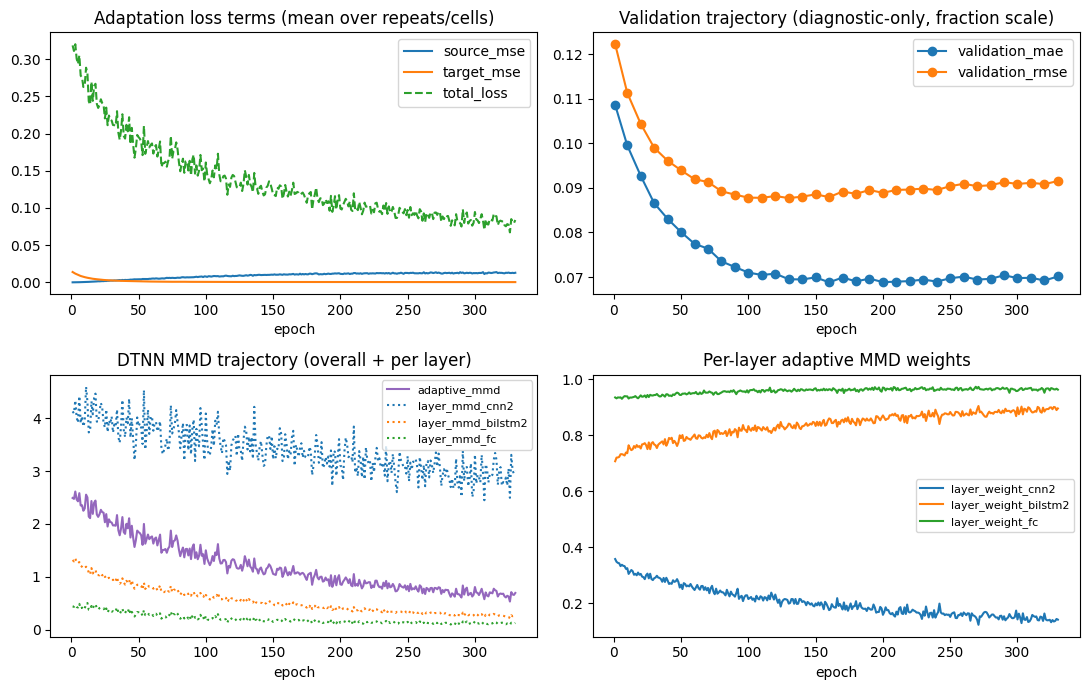

In [7]:
import matplotlib.pyplot as plt
import json

if not training_history.empty:
    epoch_mean = training_history.groupby('epoch').mean(numeric_only=True)
    validation_rows = training_history.loc[training_history['validation_evaluated']]
    validation_mean = (
        validation_rows.groupby('epoch')[['validation_mae', 'validation_rmse']].mean()
        if not validation_rows.empty else pd.DataFrame()
    )

    fig, axes = plt.subplots(2, 2, figsize=(11, 7))

    axes[0, 0].plot(epoch_mean.index, epoch_mean['source_mse'], label='source_mse')
    axes[0, 0].plot(epoch_mean.index, epoch_mean['target_mse'], label='target_mse')
    axes[0, 0].plot(epoch_mean.index, epoch_mean['total_loss'], label='total_loss', linestyle='--')
    axes[0, 0].set_title('Adaptation loss terms (mean over repeats/cells)')
    axes[0, 0].set_xlabel('epoch'); axes[0, 0].legend()

    if not validation_mean.empty:
        axes[0, 1].plot(validation_mean.index, validation_mean['validation_mae'], marker='o', label='validation_mae')
        axes[0, 1].plot(validation_mean.index, validation_mean['validation_rmse'], marker='o', label='validation_rmse')
    axes[0, 1].set_title('Validation trajectory (diagnostic-only, fraction scale)')
    axes[0, 1].set_xlabel('epoch'); axes[0, 1].legend()

    axes[1, 0].plot(epoch_mean.index, epoch_mean['adaptive_mmd'], color='tab:purple', label='adaptive_mmd')
    for layer in ('cnn2', 'bilstm2', 'fc'):
        axes[1, 0].plot(epoch_mean.index, epoch_mean[f'layer_mmd_{layer}'], linestyle=':', label=f'layer_mmd_{layer}')
    axes[1, 0].set_title('DTNN MMD trajectory (overall + per layer)')
    axes[1, 0].set_xlabel('epoch'); axes[1, 0].legend(fontsize=8)

    for layer in ('cnn2', 'bilstm2', 'fc'):
        axes[1, 1].plot(epoch_mean.index, epoch_mean[f'layer_weight_{layer}'], label=f'layer_weight_{layer}')
    axes[1, 1].set_title('Per-layer adaptive MMD weights')
    axes[1, 1].set_xlabel('epoch'); axes[1, 1].legend(fontsize=8)

    fig.tight_layout()
    plt.show()
else:
    print('No training_history.csv found at', training_history_path)


### Prediction-level diagnostics (`test_predictions.parquet`)

Per-timestep records (`framework, method, repeat, seed, cell_id, condition, split, mission_cycle_id, window_index, timestep_index, mission_sequence_order, elapsed_candidate_s, original_time_s, source_row_right, ns_raw, mission_phase, soc_reference, soc_prediction, signed_error, absolute_error, voltage_v_raw, current_a_raw, temperature_c_raw, capacity_ah, capacity_source, source_rpt_id`), already evaluated with DTNN's own `all_timesteps` convention (`run_metadata['evaluation_unit']`) -- not last-step-per-window like Vidal. `mission_phase` is derived from the raw, untouched `ns_raw` via `NS_MISSION_PHASE_MAP`; flight-phase analysis below focuses on `take_off`/`cruise`/`landing`.

,mean_abs_error_percent (all_timesteps)
method,
Bian MDA,7.049
Source only,10.211


method,Bian MDA,Source only,adapted_minus_source
cell_id,,,
VAH01,6.110,9.418,-3.309
VAH11,5.486,7.426,-1.940
VAH12,10.251,12.905,-2.654
VAH15,6.771,10.651,-3.879
VAH17,7.202,10.595,-3.393
VAH27,6.153,10.174,-4.021
VAH30,8.137,13.062,-4.925


Negative-transfer cells (adapted worse than source-only):


method,Bian MDA,Source only,adapted_minus_source
cell_id,,,


method,Bian MDA,Source only
mission_phase,,
take_off,NaN,NaN
cruise,5.693,10.415
landing,10.459,9.695


/tmp/ipykernel_3293/1723110892.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned = pred.groupby([bins, 'method'])['abs_error_percent'].mean().unstack('method')
/tmp/ipykernel_3293/1723110892.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned = pred.groupby([bins, 'method'])['abs_error_percent'].mean().unstack('method')


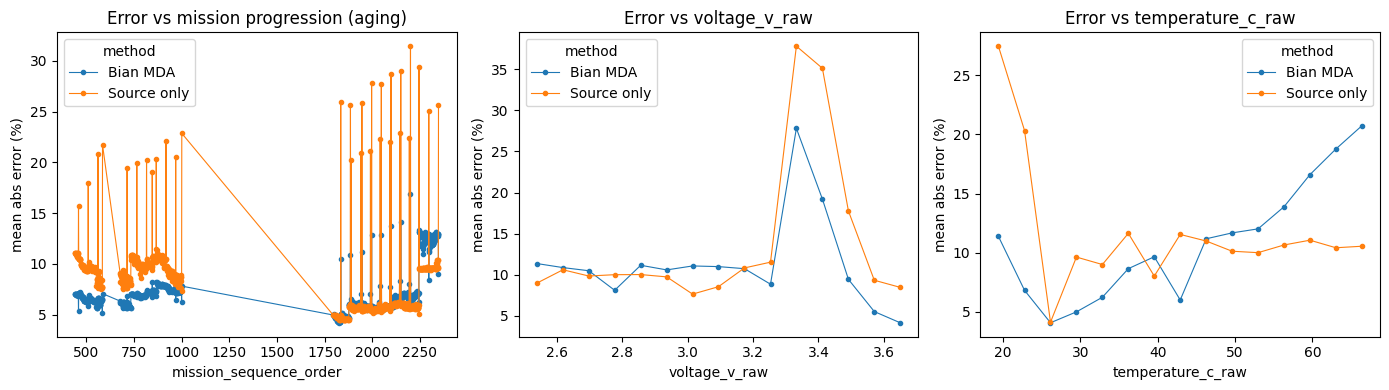

Worst 10 adapted-model missions by mean absolute error (%):


abs_error_percent
cell_id mission_cycle_id                                                     
VAH11   cmu_v3_dev_candidate_v0:VAH11:b7:s1371542:e1378804             17.582
        cmu_v3_dev_candidate_v0:VAH11:b7:s1339848:e1347110             17.151
        cmu_v3_dev_candidate_v0:VAH11:b7:s1308300:e1315562             14.255
        cmu_v3_dev_candidate_v0:VAH11:b7:s1276812:e1284074             13.991
VAH12   cmu_v3_dev_candidate_v0:VAH12:b6:s1274995:e1275056             13.184
        cmu_v3_dev_candidate_v0:VAH12:b6:s1275286:e1275347             13.150
        cmu_v3_dev_candidate_v0:VAH12:b6:s1283945:e1284006             13.146
        cmu_v3_dev_candidate_v0:VAH12:b6:s1313446:e1313507             13.126
        cmu_v3_dev_candidate_v0:VAH12:b6:s1251460:e1251521             13.125
        cmu_v3_dev_candidate_v0:VAH12:b6:s1258085:e1258146             13.106

In [8]:
if not test_predictions.empty:
    pred = test_predictions.copy()
    pred['abs_error_percent'] = pred['absolute_error'] * 100  # fraction -> percent for readability only

    # Source-only vs adapted overall error, and per-cell transfer gain
    # (cross-check against metrics.csv/summary.csv -- same soc_reference/
    # soc_prediction columns, recomputed here directly from the saved
    # per-timestep records rather than re-running evaluation).
    overall_by_method = pred.groupby('method')['abs_error_percent'].mean().round(3)
    display(overall_by_method.rename('mean_abs_error_percent (all_timesteps)').to_frame())

    per_cell_gain = (
        pred.groupby(['cell_id', 'method'])['abs_error_percent'].mean()
        .unstack('method')
    )
    if {'Source only', 'Bian MDA'} <= set(per_cell_gain.columns):
        per_cell_gain['adapted_minus_source'] = (
            per_cell_gain['Bian MDA'] - per_cell_gain['Source only']
        )
        display(per_cell_gain.round(3))
        negative_transfer_cells = per_cell_gain.loc[per_cell_gain['adapted_minus_source'] > 0]
        print('Negative-transfer cells (adapted worse than source-only):')
        display(negative_transfer_cells.round(3))

    # Flight-phase (take_off/cruise/landing) error, by method.
    flight_phases = ('take_off', 'cruise', 'landing')
    phase_error = (
        pred.loc[pred['mission_phase'].isin(flight_phases)]
        .groupby(['mission_phase', 'method'])['abs_error_percent'].mean()
        .unstack('method').reindex(flight_phases)
    )
    display(phase_error.round(3))

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    # Error vs mission progression (aging proxy: sequence order within the cell's timeline).
    progression = (
        pred.groupby(['mission_sequence_order', 'method'])['abs_error_percent'].mean()
        .unstack('method')
    )
    progression.plot(ax=axes[0], marker='.', linewidth=0.8)
    axes[0].set_title('Error vs mission progression (aging)')
    axes[0].set_xlabel('mission_sequence_order'); axes[0].set_ylabel('mean abs error (%)')

    # Error vs raw operating conditions (voltage/current/temperature).
    for column, ax_index in (('voltage_v_raw', 1), ('temperature_c_raw', 2)):
        bins = pd.cut(pred[column], bins=15)
        binned = pred.groupby([bins, 'method'])['abs_error_percent'].mean().unstack('method')
        binned.index = [interval.mid for interval in binned.index]
        binned.plot(ax=axes[ax_index], marker='.', linewidth=0.8)
        axes[ax_index].set_title(f'Error vs {column}')
        axes[ax_index].set_xlabel(column); axes[ax_index].set_ylabel('mean abs error (%)')

    fig.tight_layout()
    plt.show()

    # Negative-transfer case inspection: worst individual test missions
    # for the adapted model (largest per-mission mean absolute error),
    # with their flight-phase and raw-condition context for spot review.
    adapted = pred.loc[pred['method'] == 'Bian MDA']
    worst_missions = (
        adapted.groupby(['cell_id', 'mission_cycle_id'])['abs_error_percent']
        .mean().sort_values(ascending=False).head(10)
    )
    print('Worst 10 adapted-model missions by mean absolute error (%):')
    display(worst_missions.round(3).to_frame())
else:
    print('No test_predictions.parquet found at', test_predictions_path)


## Full-mission diagnostic (RQ3/RQ4) -- separate from primary evaluation

Everything below reads `test_predictions_full_mission_diagnostic.parquet`, `phase_metrics_full_mission_diagnostic.csv`, and `phase_transfer_effects_full_mission_diagnostic.csv` -- diagnostic-only outputs covering each test mission's ENTIRE timeline (no `initial_soc` truncation, no adapt/test 30/70 split), used only for RQ3/RQ4 phase and negative-transfer analysis. `run_metadata['full_mission_diagnostic']` documents that this never participates in training, early stopping, or checkpoint selection, and never replaces the primary benchmark metrics above. Kept in its own table/plots throughout -- never merged into the primary performance table above.

In [9]:
full_mission_predictions_path = RESULT_ROOT / 'test_predictions_full_mission_diagnostic.parquet'
phase_metrics_path = RESULT_ROOT / 'phase_metrics_full_mission_diagnostic.csv'
phase_transfer_effects_path = RESULT_ROOT / 'phase_transfer_effects_full_mission_diagnostic.csv'

full_mission_predictions = (
    pd.read_parquet(full_mission_predictions_path)
    if full_mission_predictions_path.exists() else pd.DataFrame()
)
phase_metrics = pd.read_csv(phase_metrics_path) if phase_metrics_path.exists() else pd.DataFrame()
phase_transfer_effects = (
    pd.read_csv(phase_transfer_effects_path) if phase_transfer_effects_path.exists() else pd.DataFrame()
)
print('full-mission diagnostic predictions rows:', len(full_mission_predictions))
if run_metadata:
    print('primary_evaluation_scope:', run_metadata.get('primary_evaluation_scope'))
    print('full_mission_diagnostic:', run_metadata.get('full_mission_diagnostic'))


full-mission diagnostic predictions rows: 17425800
primary_evaluation_scope: initial_soc_70_then_test_70_percent
full_mission_diagnostic: {'enabled': True, 'purpose': 'RQ3/RQ4 full-mission phase and negative-transfer analysis only', 'used_for_training': False, 'used_for_adaptation': False, 'used_for_early_stopping': False, 'used_for_checkpoint_selection': False, 'replaces_primary_benchmark_metrics': False, 'test_missions': "identical to the primary test split's mission ids", 'truncation': 'none -- full mission, first row to last row', 'adapt_test_split_applied': False, 'normalization': 'identical source-global min-max as the primary split', 'sequence_length': 'identical to the primary split', 'evaluation_unit': 'all_timesteps (same convention as the primary split)', 'outputs': ['test_predictions_full_mission_diagnostic.parquet', 'phase_metrics_full_mission_diagnostic.csv', 'phase_transfer_effects_full_mission_diagnostic.csv']}


In [10]:
if not phase_metrics.empty:
    display(
        phase_metrics.sort_values(['cell_id', 'method', 'mission_phase']).reset_index(drop=True)
    )
else:
    print('No phase_metrics_full_mission_diagnostic.csv found at', phase_metrics_path)


,repeat,seed,cell_id,method,mission_phase,n_points,n_missions,mae_percent,rmse_percent,mean_signed_error_percent
0,1,1,VAH01,Bian MDA,cruise,161600,170,3.781652,4.567621,-3.601886
1,2,2,VAH01,Bian MDA,cruise,161600,170,5.514360,6.810844,1.140932
2,3,3,VAH01,Bian MDA,cruise,161600,170,5.887782,6.607936,-3.653499
3,4,4,VAH01,Bian MDA,cruise,161600,170,4.732374,5.606585,-2.960620
4,5,5,VAH01,Bian MDA,cruise,161600,170,4.844825,6.035021,-3.124644
...,...,...,...,...,...,...,...,...,...,...
205,1,1,VAH30,Source only,take_off,13695,185,11.166303,11.429758,-11.166303
206,2,2,VAH30,Source only,take_off,13695,185,5.015778,5.854820,-4.914651
207,3,3,VAH30,Source only,take_off,13695,185,9.594765,9.990858,-9.594765
208,4,4,VAH30,Source only,take_off,13695,185,12.652002,13.065461,-12.652002


In [11]:
if not phase_transfer_effects.empty:
    display(
        phase_transfer_effects.sort_values(['cell_id', 'mission_phase']).reset_index(drop=True)
    )
    negative_transfer_summary = (
        phase_transfer_effects
        .groupby('mission_phase')[['negative_transfer_mae', 'negative_transfer_rmse']]
        .mean()
        .round(3)
    )
    print('Fraction of (repeat, seed, cell) combinations showing negative transfer, by phase:')
    display(negative_transfer_summary)
else:
    print('No phase_transfer_effects_full_mission_diagnostic.csv found at', phase_transfer_effects_path)


,repeat,seed,cell_id,mission_phase,delta_mae_percent,delta_rmse_percent,negative_transfer_mae,negative_transfer_rmse
0,1,1,VAH01,cruise,-4.882446,-5.423978,False,False
1,2,2,VAH01,cruise,-6.038382,-5.559098,False,False
2,3,3,VAH01,cruise,-1.725863,-2.652740,False,False
3,4,4,VAH01,cruise,-2.095792,-3.197738,False,False
4,5,5,VAH01,cruise,-3.590771,-3.639737,False,False
...,...,...,...,...,...,...,...,...
100,1,1,VAH30,take_off,3.088615,3.452407,True,True
101,2,2,VAH30,take_off,1.920614,1.374050,True,True
102,3,3,VAH30,take_off,-7.176064,-5.500002,False,False
103,4,4,VAH30,take_off,1.366036,1.672106,True,True


Fraction of (repeat, seed, cell) combinations showing negative transfer, by phase:


,negative_transfer_mae,negative_transfer_rmse
mission_phase,,
cruise,0.200,0.000
landing,0.600,0.543
take_off,0.543,0.543
